# 01 - Data acquisition & EDA
Heart Disease UCI (Cleveland). Run the cells top to bottom.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
os.chdir('..')
%matplotlib inline

In [2]:
!python scripts/download_data.py
from src.data import load_raw, clean, load_clean
raw = load_raw()
raw.head()

INFO Raw data already present at C:\mlops\heart-disease-mlops\data\raw\heart_disease_raw.csv (use --force to refresh)
INFO Saved cleaned data -> C:\mlops\heart-disease-mlops\data\processed\heart_clean.csv | shape=(303, 14) | positives=45.9%


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Raw data quality
Missing values are encoded as `?` in the source file.

In [3]:
print(raw.shape)
raw.isna().sum()[lambda s: s > 0]

(303, 14)


ca      4
thal    2
dtype: int64

In [4]:
df = clean(raw)
print(df.shape, 'positives:', df['target'].mean().round(3))
df.describe().T

(303, 14) positives: 0.459


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## Generate all EDA figures (saved to `reports/figures/`)

In [5]:
from src.eda import run_eda
summary = run_eda(df)
summary

{'rows': 303,
 'columns': 14,
 'class_counts': {'0': 164, '1': 139},
 'positive_rate': 0.45874587458745875,
 'missing_values': {'ca': 4, 'thal': 2},
 'top_correlations_with_target': {'thal': 0.526,
  'ca': 0.46,
  'exang': 0.432,
  'oldpeak': 0.425,
  'thalach': -0.417,
  'cp': 0.414},
 'figures': ['eda_class_balance.png',
  'eda_missing_values.png',
  'eda_numeric_histograms.png',
  'eda_numeric_boxplots.png',
  'eda_categorical_counts.png',
  'eda_correlation_heatmap.png']}

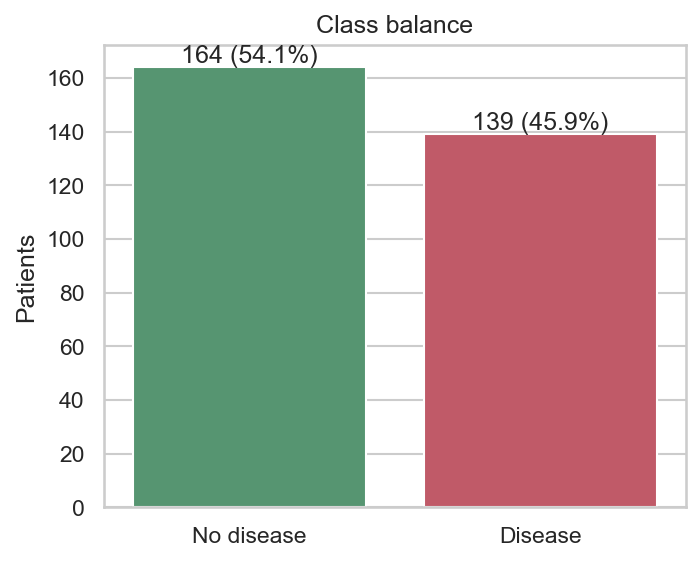

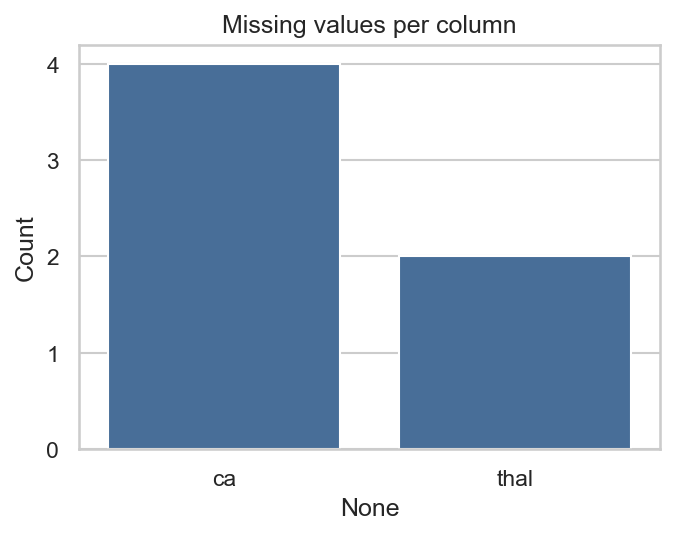

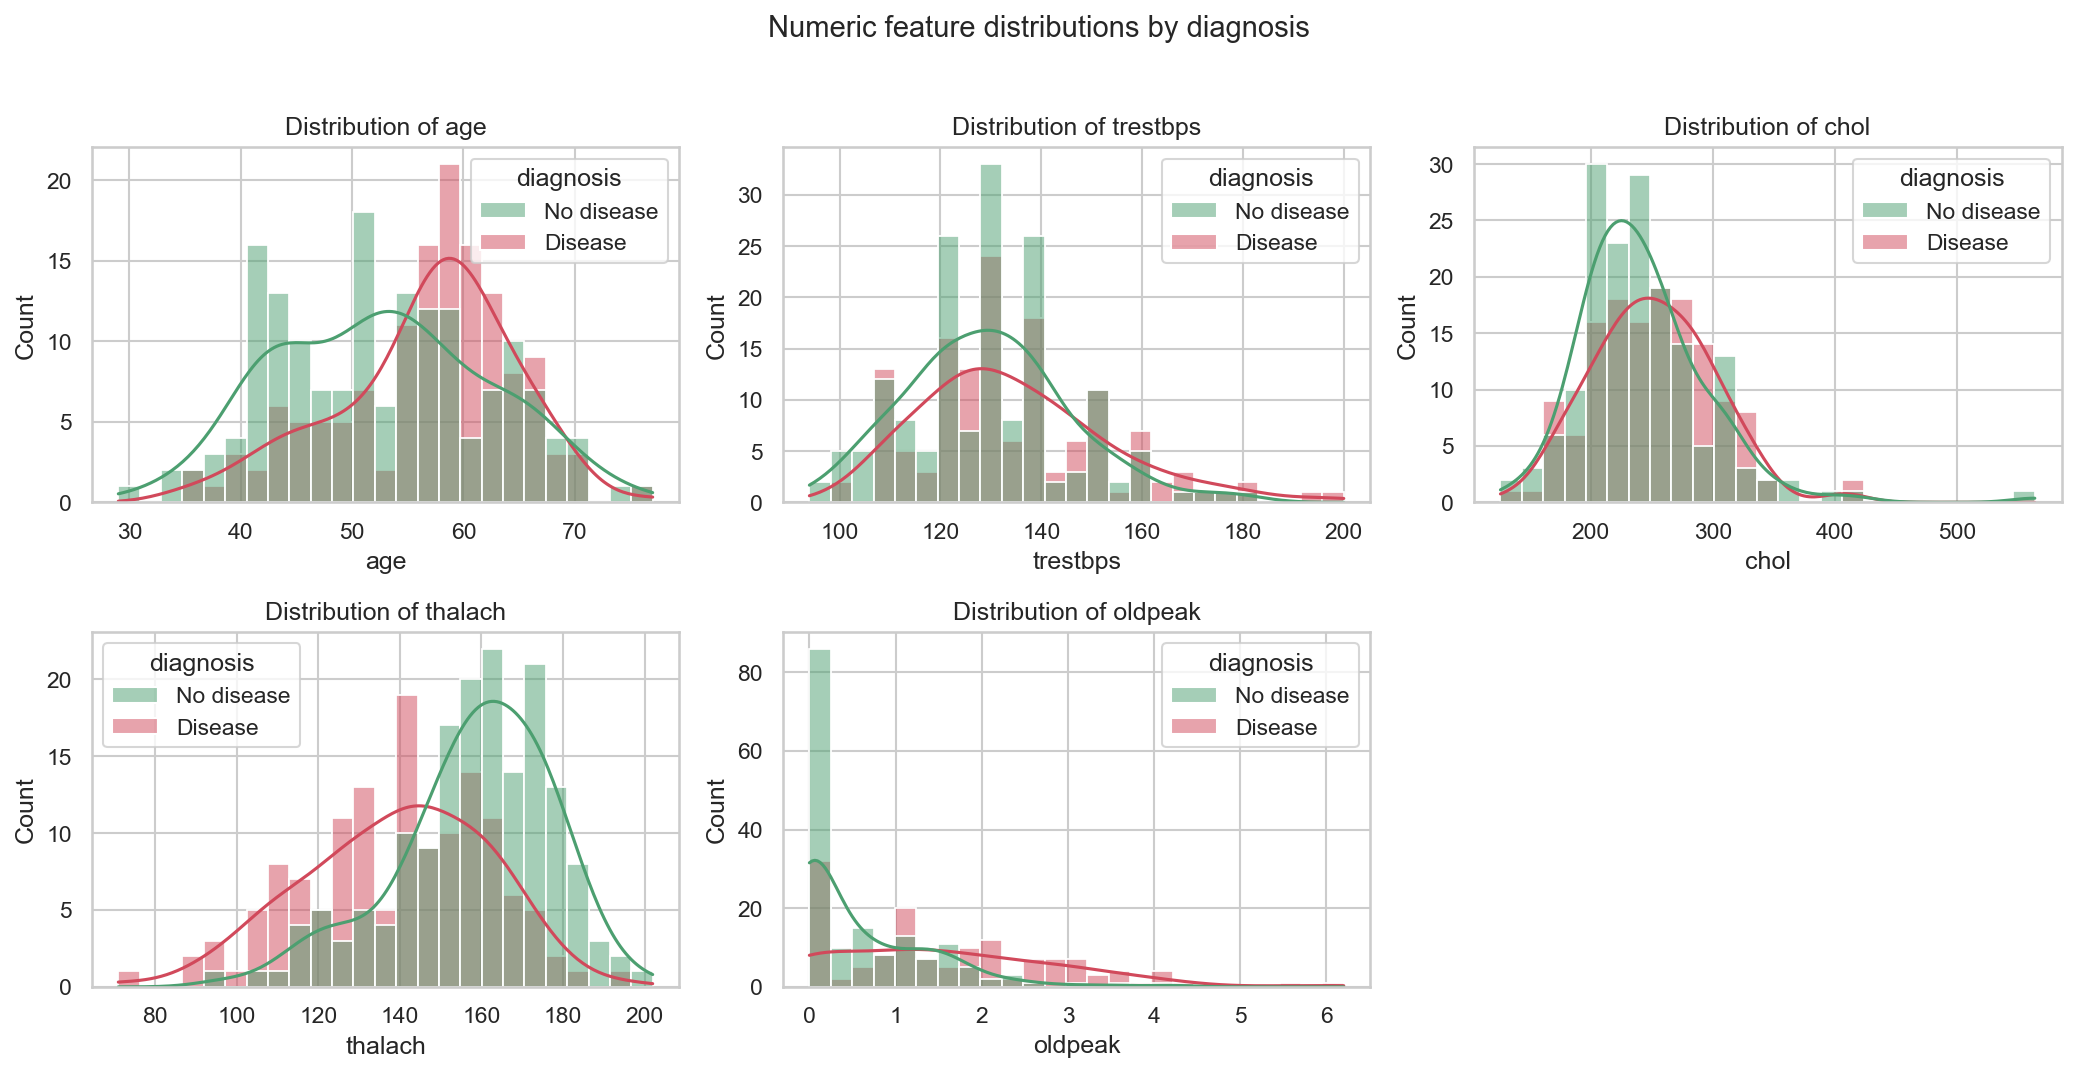

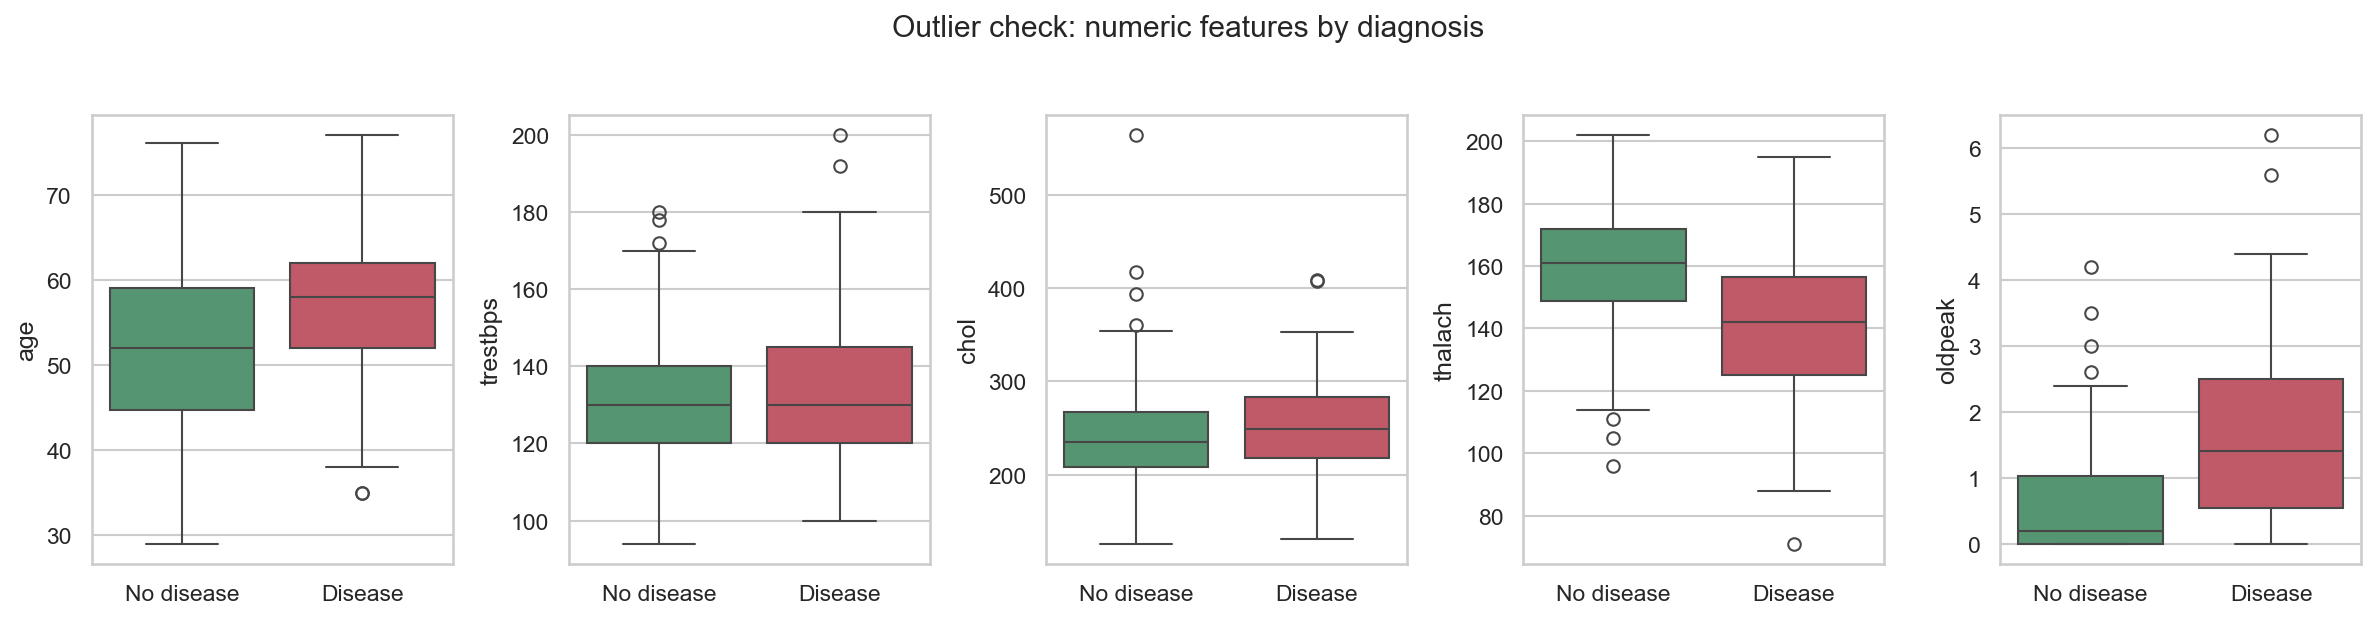

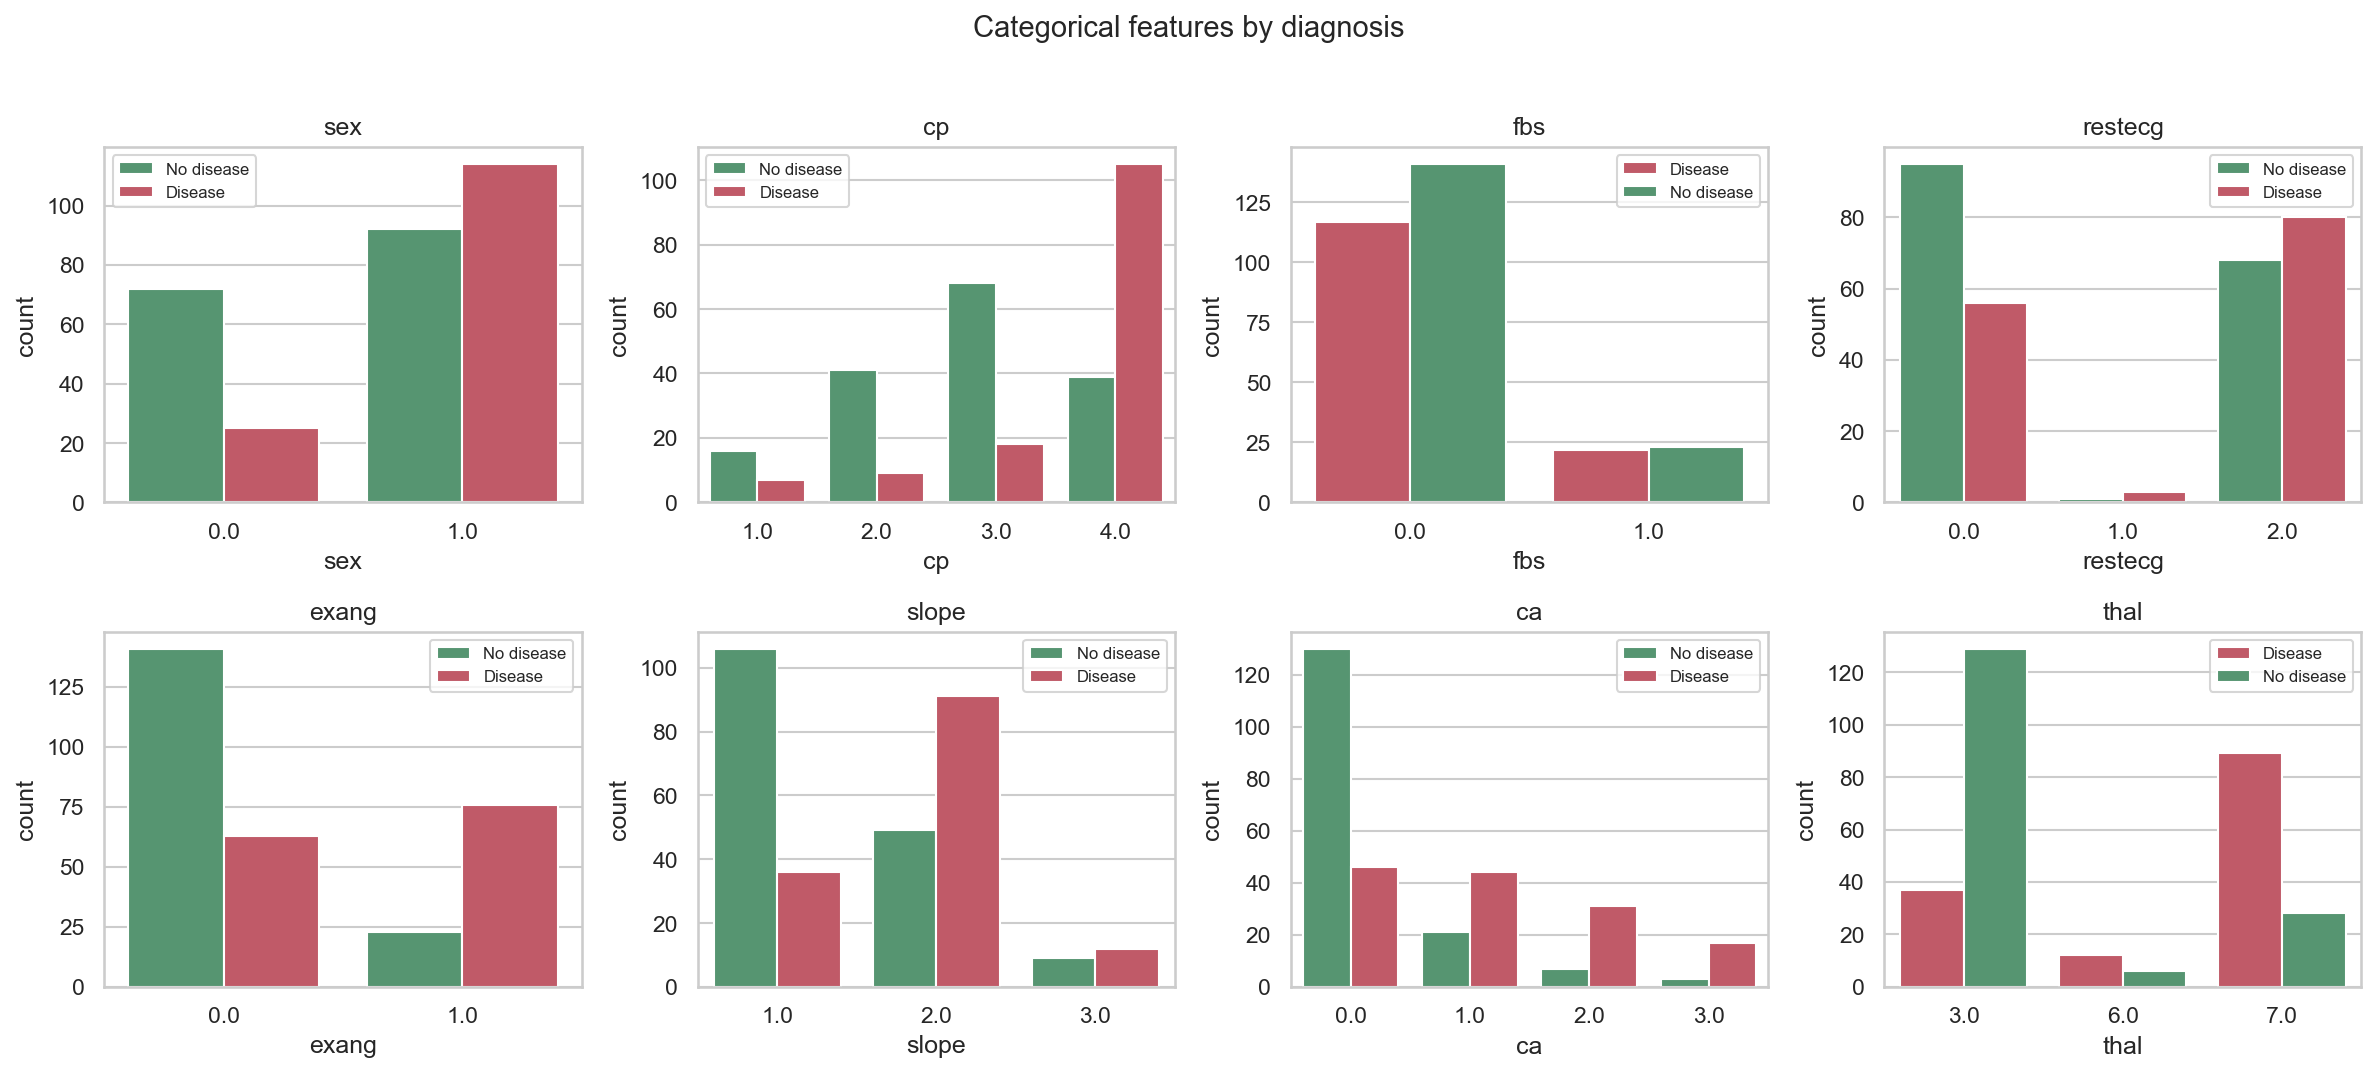

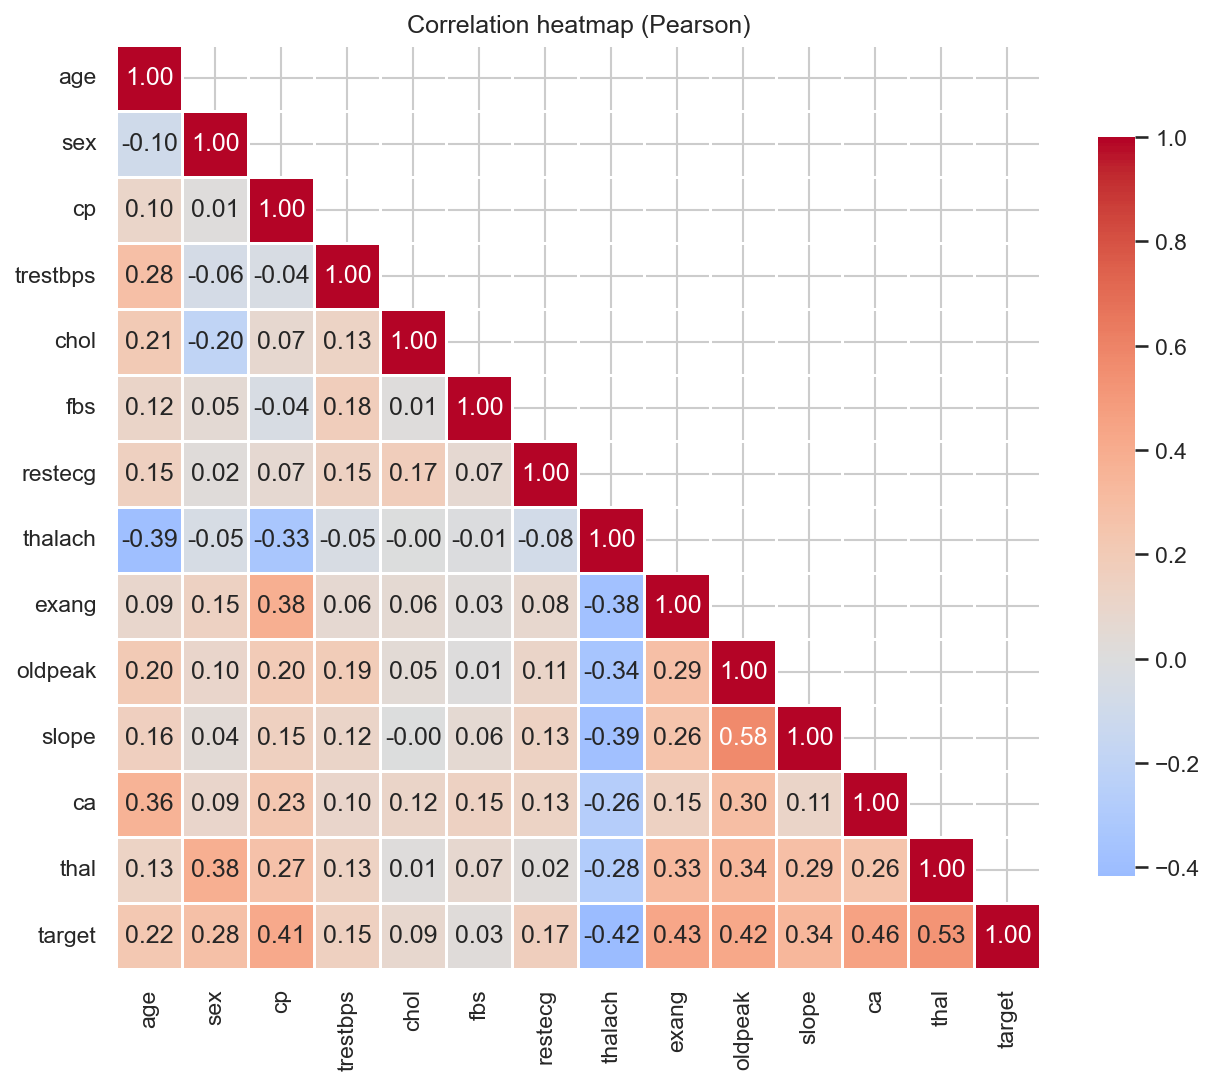

In [6]:
from IPython.display import Image, display
for f in summary['figures']:
    display(Image(f'reports/figures/{f}'))

# Observations

Data quality and class balance

The dataset has 303 patients: 164 without heart disease (54.1%) and 139 with it (45.9%). The classes are nearly balanced, so no resampling is needed and accuracy is a meaningful metric. I still use a stratified split and prioritise recall and ROC-AUC, because missing a sick patient is costlier than a false alarm.
Only two columns have missing values: ca (4 rows) and thal (2 rows), about 2% of patients. They are too few to justify dropping rows, so they are imputed inside the pipeline (median or most-frequent) to avoid leakage.

Numeric features

thalach (max heart rate) separates the classes well. Patients with disease peak around 145 bpm, healthy patients around 160 to 165, and the boxplot medians are about 142 vs 161.
oldpeak (ST depression) is strongly right-skewed. Most healthy patients sit at or near 0 (about 85 patients in the first bin), while the disease group has a median of about 1.4 and a long tail up to about 6.
age is higher in the disease group (median about 58 vs 52), and disease cases cluster around 55 to 65.
trestbps (resting blood pressure) and chol (cholesterol) overlap heavily between classes with almost identical medians (about 130 and about 235 to 250). They are weak individual predictors.

Outliers

The boxplots show a few extreme points: one chol value above 550, trestbps near 200, oldpeak above 5.5, and one very low thalach (about 70). These are medically possible values and not data-entry errors, so I kept them. StandardScaler and tree-based models handle them reasonably.

Categorical features

Chest pain type cp = 4 (asymptomatic) is the strongest category: about 105 of roughly 145 patients with this value have disease. Types 1 to 3 are mostly healthy.
Exercise-induced angina (exang = 1) is mostly disease (about 76 vs 22), and exang = 0 is mostly healthy.
thal = 7 (reversible defect) is mostly disease (about 89 vs 28), while thal = 3 (normal) is mostly healthy (about 129 vs 37).
For ca (vessels coloured), 0 vessels is mostly healthy (about 130 vs 46), and 1 or more vessels shifts toward disease.
The slope of the ST segment follows the pattern too: slope = 2 is mostly disease (about 91 vs 49) and slope = 1 is mostly healthy (about 106 vs 36).
Males (sex = 1) have a much higher disease share (about 55%) than females (about 26%).
fbs shows almost no separation, and restecg = 1 has only a handful of patients.

Correlations

The features most correlated with the target are thal (0.53), ca (0.46), exang (0.43), oldpeak (0.42) and cp (0.41). thalach is the strongest negative one (−0.42). fbs (0.03) and chol (0.09) are nearly uncorrelated with the target.
The highest correlation between two features is slope vs oldpeak (0.58). No pair exceeds 0.6, so there is no serious multicollinearity, and logistic regression is safe to use.

Implications for modelling

These findings led me to one-hot encode the categorical features (their codes are labels, not quantities), scale the numeric ones, and add a hr_reserve_pct feature that compares max heart rate to the age-predicted maximum, because thalach and age are both informative and correlated (−0.39).`

* Class balance: `[[54% positive]]` - roughly balanced, so accuracy is meaningful but recall is still prioritised
  because a missed diagnosis is costlier than a false alarm.
* Features most correlated with target: `thal (0.53), ca (0.46), exang (0.43), oldpeak (0.42) and cp (0.41)`.
* Outliers: `chol > 500, oldpeak > 5, trestbps > 200` - kept (clinically plausible), scaled with StandardScaler.
* Which categorical values separate classes most (cp = 4, exang = 1, thal = 7 ...): `thal`.